In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv('../data/cleaned/cleaned_retails.csv')

In [3]:
# check head and tails
df.head()


,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Normal / Other
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal / Other
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Normal / Other
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal / Other
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal / Other


In [4]:
display(df.tail())

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
536636,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,Normal / Other
536637,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,Normal / Other
536638,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,Normal / Other
536639,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,Normal / Other
536640,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,Normal / Other


In [5]:
df['invoicedate'] = pd.to_datetime(df['invoicedate'])

# fill missing descriptions from the same stockcode
df['description'] = df['description'].fillna(
    df.groupby('stockcode')['description'].transform('first'))

## country Analysis 
  purpose: which country has higher no of orders.
   

# Question: 
    1. Which country has higher no  of orders?
    2. is the dataset orders has balance ?
    3. Which country has less no of orderes or need to focused?
    

In [6]:
country_value_count = df['country'].value_counts()

country_PCT = round(df['country'].value_counts(normalize=True) * 100 ,2)

pd.DataFrame({
    "Count" : country_value_count,
    "Percentage": country_PCT
}).head(10)

,Count,Percentage
country,,
United Kingdom,490300,91.36
Germany,9480,1.77
France,8541,1.59
Ireland,8184,1.53
Spain,2528,0.47
Netherlands,2371,0.44
Belgium,2069,0.39
Switzerland,1994,0.37
Portugal,1510,0.28


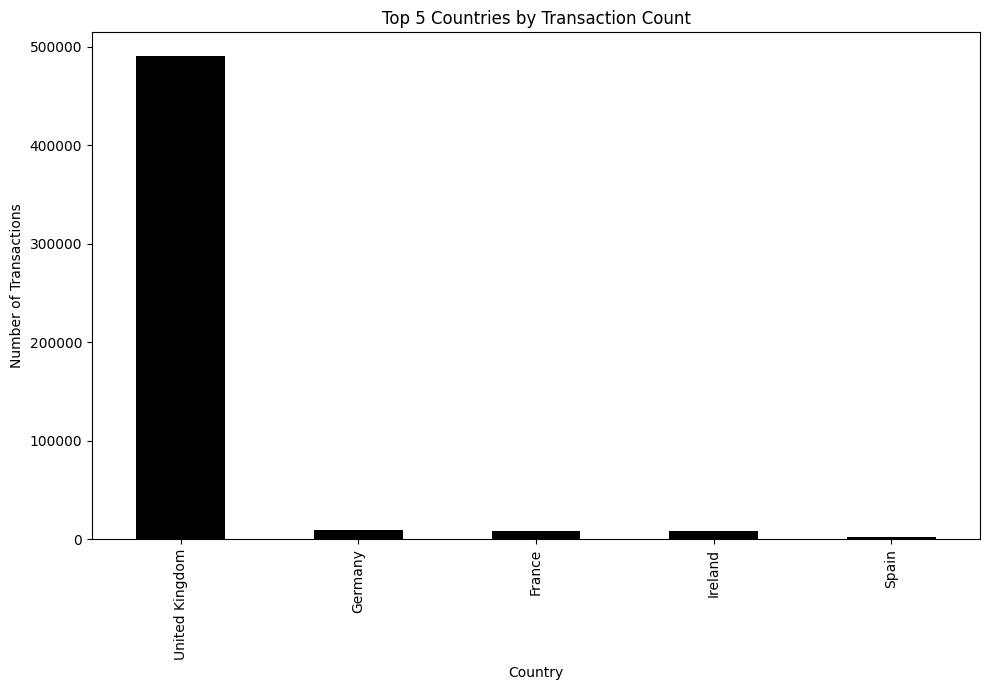

In [7]:
plt.figure(figsize=(10, 7))

country_value_count.sort_values(ascending=False).head(5).plot(
    kind='bar',
    color='black'
)

plt.title("Top 5 Countries by Transaction Count")
plt.ylabel("Number of Transactions")
plt.xlabel("Country")

plt.tight_layout()
plt.show()

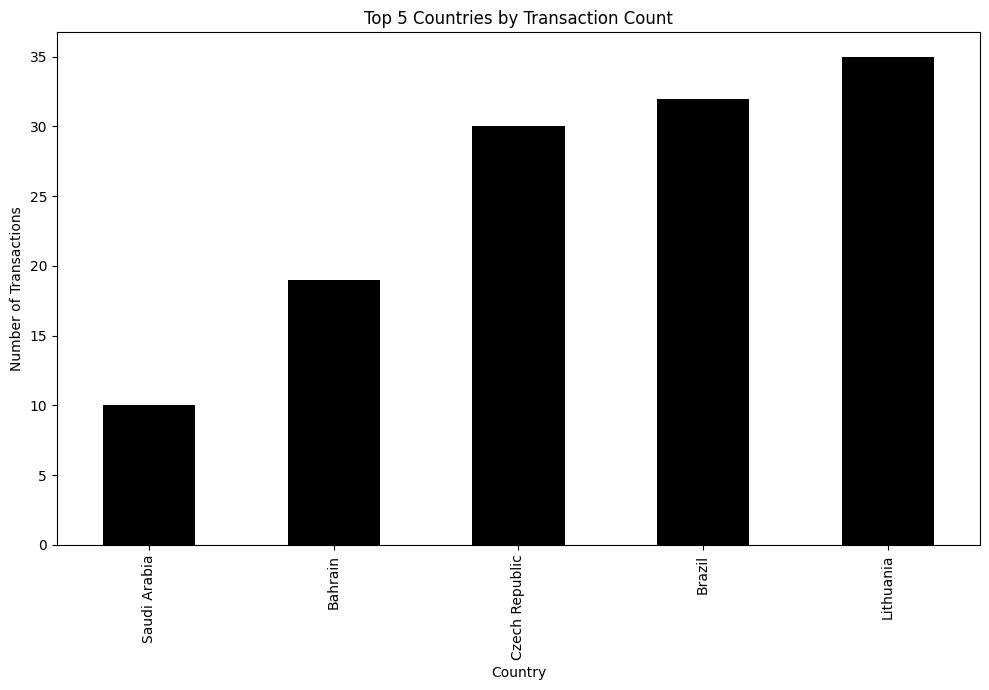

In [8]:
plt.figure(figsize=(10, 7))

country_value_count.sort_values(ascending=True).head(5).plot(
    kind='bar',
    color='black'
)

plt.title("Top 5 Countries by Transaction Count")
plt.ylabel("Number of Transactions")
plt.xlabel("Country")

plt.tight_layout()
plt.show()

In [9]:
# Analysis transaction_type

transaction_type_count = df['transaction_type'].value_counts()
transaction_pct =round(df['transaction_type'].value_counts() /len(df)* 100 ,2)

pd.DataFrame({
    'Count' : transaction_type_count,
    'Perecntage': transaction_pct
})

,Count,Perecntage
transaction_type,,
Normal / Other,527387,98.28
Cancellation,9251,1.72
Accounting Adjustment,3,0.00


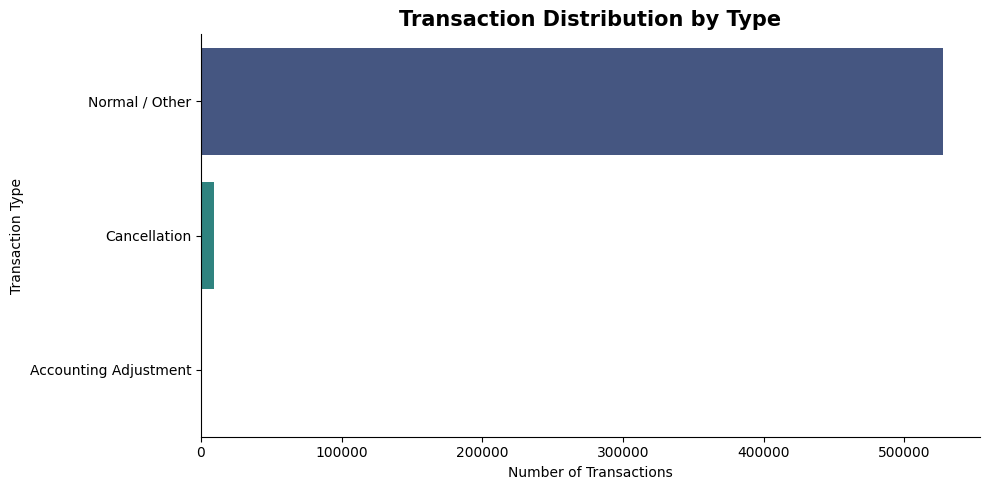

In [10]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=transaction_type_count.values,
    y=transaction_type_count.index,
    hue=transaction_type_count.index,
    palette='viridis',
    legend=False
)

plt.title('Transaction Distribution by Type',
          fontsize=15, fontweight='bold')

plt.xlabel('Number of Transactions')
plt.ylabel('Transaction Type')

sns.despine()
plt.tight_layout()
plt.show()

In [11]:
df['unitprice'].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: unitprice, dtype: float64

In [12]:
print('Positive Unitpirce:', (df['unitprice'] > 0).sum())
print('Zero Unitpirce:', (df['unitprice'] == 0).sum())
print('Negative Unitpirce:', (df['unitprice'] < 0).sum())
print('Unique Unitpirce:', (df['unitprice'].nunique()))
print('Null Unitpirce:', (df['unitprice'].isna()).sum())

Positive Unitpirce: 534129
Zero Unitpirce: 2510
Negative Unitpirce: 2
Unique Unitpirce: 1630
Null Unitpirce: 0


In [13]:
df[df['unitprice'] == 0]

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type
605,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,Normal / Other
1934,536545,21134,None,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,Normal / Other
1935,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal / Other
1936,536547,37509,NEW ENGLAND MUG W GIFT BOX,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,Normal / Other
1951,536549,85226A,None,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,Normal / Other
...,...,...,...,...,...,...,...,...,...
531753,581234,72817,SET OF 2 CHRISTMAS DECOUPAGE CANDLE,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom,Normal / Other
533259,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom,Normal / Other
533260,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom,Normal / Other
533309,581408,85175,CACTI T-LIGHT CANDLES,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom,Normal / Other


In [60]:
df[df['stockcode'] == '22139']['description'].value_counts(dropna=False)

description
RETROSPOT TEA SET CERAMIC 11 PC    985
Name: count, dtype: int64

In [61]:
df.loc[
    df['stockcode'] == '22139',
    'description'
] = 'RETROSPOT TEA SET CERAMIC 11 PC'

df[df['stockcode'] == '22139']['description'].value_counts(dropna=False)

description
RETROSPOT TEA SET CERAMIC 11 PC    985
Name: count, dtype: int64

In [65]:
df.loc[
    (df['quantity'] < 0) &
    (~df['invoiceno'].astype(str).str.startswith('C')),
    'transaction_type'
] = 'Cancellation'

In [62]:
stock_median_price = (
    df[df['unitprice'] > 0]
    .groupby('stockcode')['unitprice']
    .median()
)

In [67]:
df['unitprice'].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: unitprice, dtype: float64

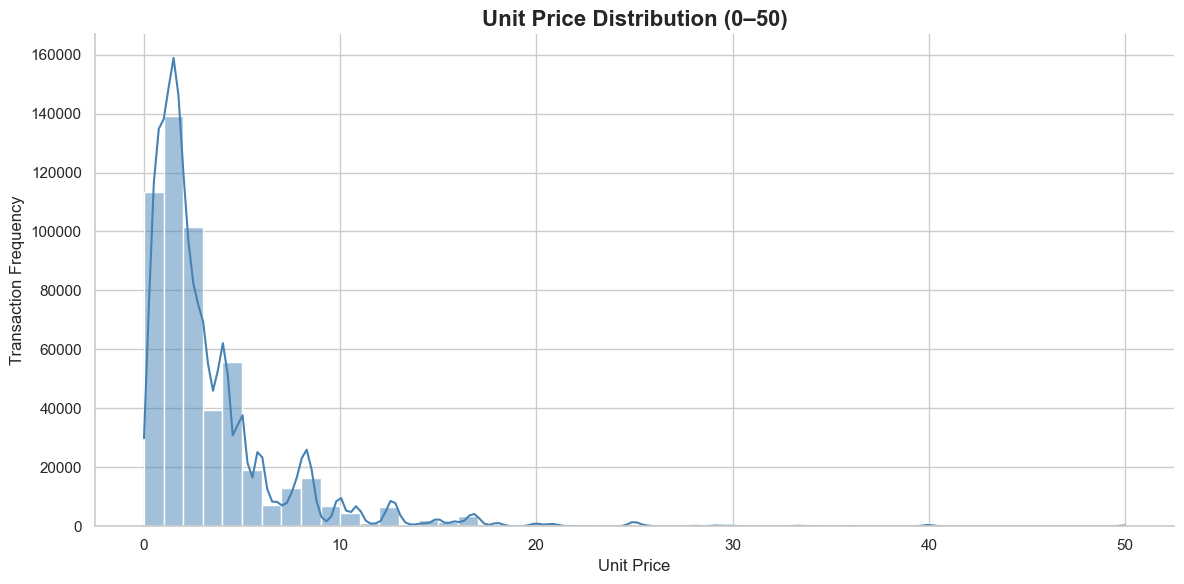

In [66]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df[df['unitprice'].between(0, 50)],
    x='unitprice',
    bins=50,
    kde=True,
    color='steelblue',
    edgecolor='white'
)

plt.title('Unit Price Distribution (0–50)',
          fontsize=16, fontweight='bold')

plt.xlabel('Unit Price')
plt.ylabel('Transaction Frequency')

sns.despine()
plt.tight_layout()
plt.show()

In [63]:
# ===================================
# unit price outlier check 
#====================================


# calculate outlier and iqr
Q1 = df['unitprice'].quantile(0.25)
Q3 = df['unitprice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


print("lower limit :", lower_limit)
print("upper limit: ", upper_limit)

# now EXtract outlier 

outliers = df[
    (df['unitprice'] < lower_limit)|
    (df['unitprice'] > upper_limit)
].copy()


# negative and positive outliers 
negative_outlier = outliers[
    outliers['unitprice'] < lower_limit
]

positive_outlier = outliers[
    outliers['unitprice'] > upper_limit ]


print("###########################")
print("Outlier Summery!")
print("Total Record:" , len(df))
print("Total Outliers: ", len(outliers))
print("Negative Outliers :", len(negative_outlier))
print("Positive Outliers: ", len(positive_outlier))
print("Outlier Percentage:", round(len(outliers) / len(df) * 100 , 2), "%")
      


lower limit : -3.0700000000000003
upper limit:  8.45
###########################
Outlier Summery!
Total Record: 536641
Total Outliers:  39450
Negative Outliers : 2
Positive Outliers:  39448
Outlier Percentage: 7.35 %


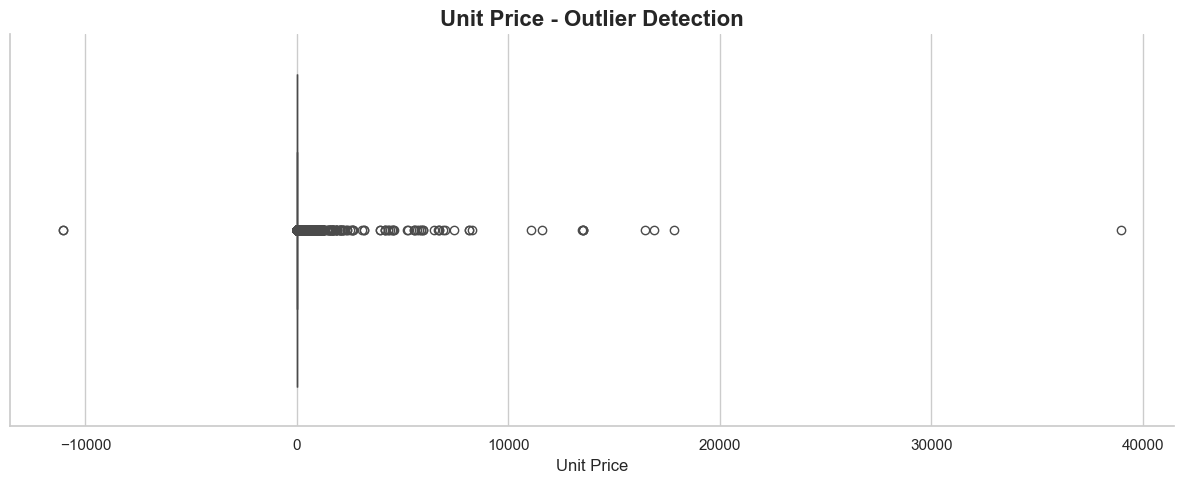

In [64]:
#  Visualize Outliers
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df['unitprice'],
    color='steelblue',
    showfliers=True
)

plt.title(
    'Unit Price - Outlier Detection',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Unit Price', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# higher price outlier 
display(
    positive_outlier.sort_values(
        by='unitprice',
        ascending=False
    )[['invoiceno', 'stockcode', 'description',
    'quantity', 'unitprice', 'customerid','transaction_type']].head()
)

In [37]:
df['year'] = df['invoicedate'].dt.year
df['month'] = df['invoicedate'].dt.month
df['day_name']= df['invoicedate'].dt.day_name()
df['month'] = df['invoicedate'].dt.strftime('%B')



df['revenue'] = df['quantity'] * df['unitprice']
df[['invoicedate', 'year', 'month', 'day_name', 'revenue']].head()

,invoicedate,year,month,day_name,revenue
0,2010-12-01 08:26:00,2010,December,Wednesday,15.30
1,2010-12-01 08:26:00,2010,December,Wednesday,20.34
2,2010-12-01 08:26:00,2010,December,Wednesday,22.00
3,2010-12-01 08:26:00,2010,December,Wednesday,20.34
4,2010-12-01 08:26:00,2010,December,Wednesday,20.34


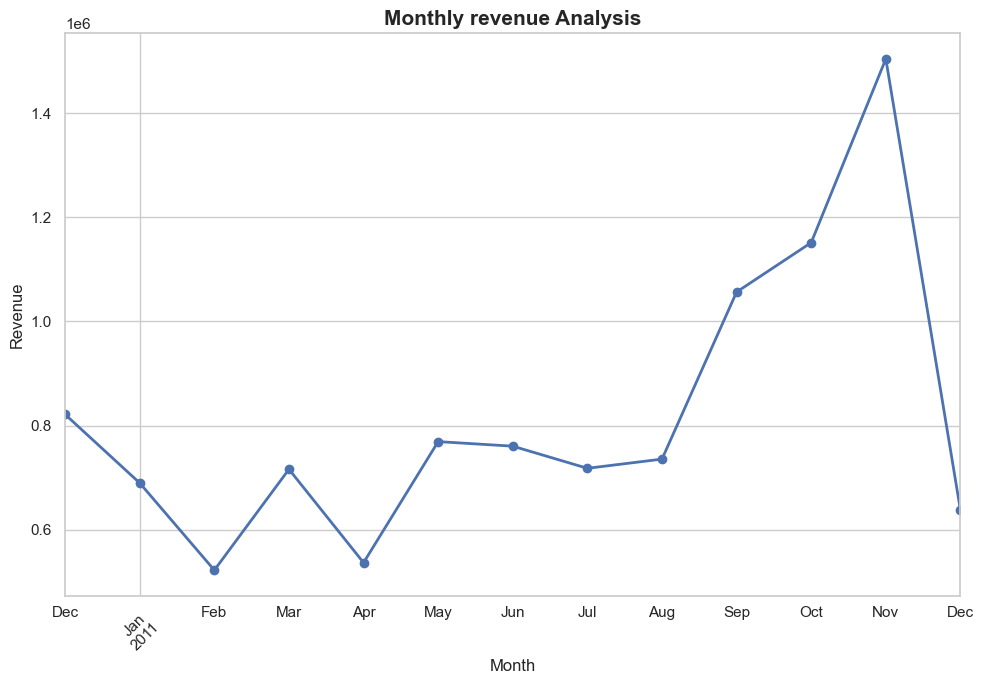

In [41]:
Monthly_revenue = (df[df['quantity'] > 0].groupby(df['invoicedate'].dt.to_period("M"))['revenue'].sum())


plt.figure(figsize=(10, 7))

Monthly_revenue.plot(
    kind='line',
    marker='o',
    linewidth=2 )

plt.title("Monthly revenue Analysis" , fontsize=15, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

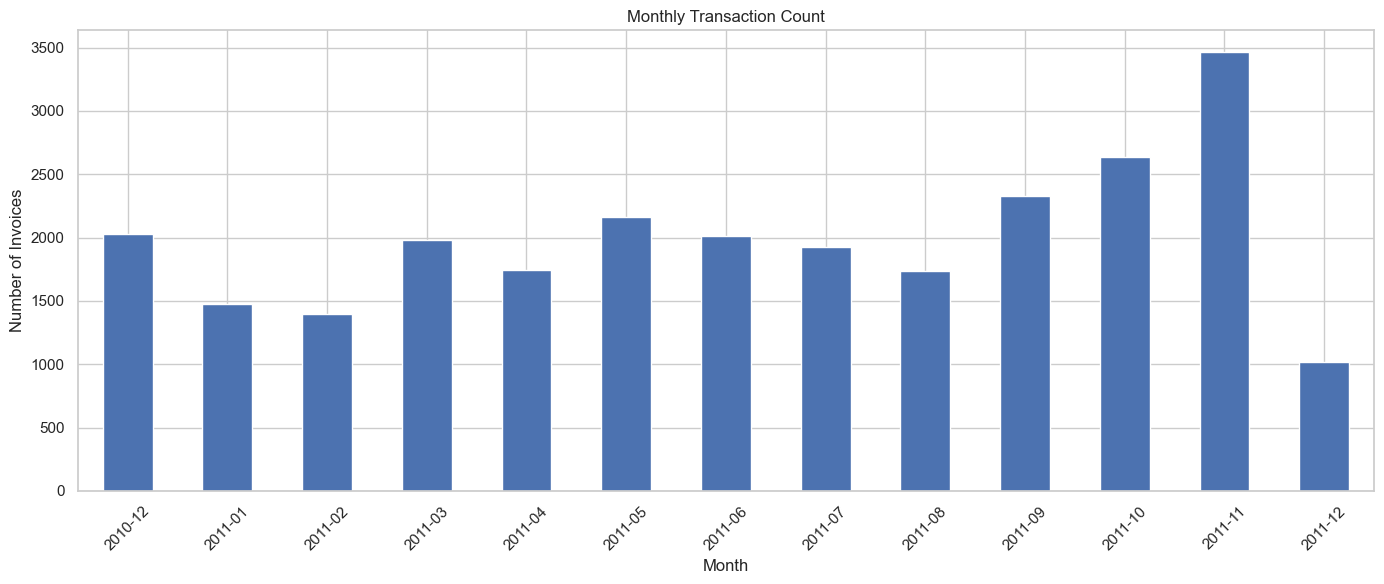

In [42]:
monthly_transactions = (
    df.groupby(df['invoicedate'].dt.to_period('M'))['invoiceno']
    .nunique()
)

plt.figure(figsize=(14, 6))

monthly_transactions.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Monthly Transaction Count')
plt.xlabel('Month')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_analysis = (
    df[df['quantity'] > 0]
    .groupby('day_name')
    .agg(
        transactions=('invoiceno', 'nunique'),
        revenue=('revenue', 'sum')
    )
    .reindex(day_order)
)

display(day_analysis)

,transactions,revenue
day_name,,
Monday,3237.0,1775782.071
Tuesday,3717.0,2175700.511
Wednesday,3865.0,1847074.380
Thursday,4408.0,2199292.570
Friday,3294.0,1815346.371
Saturday,NaN,NaN
Sunday,2207.0,806790.781


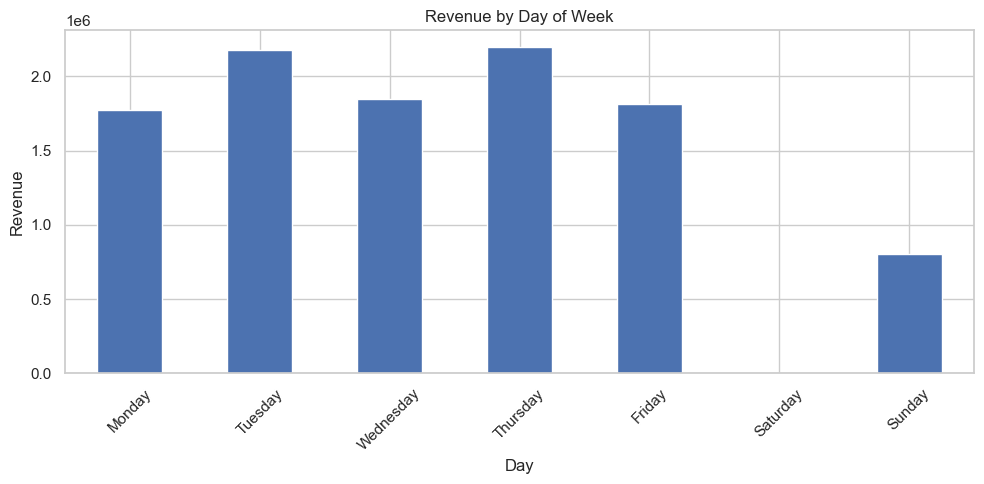

In [44]:
day_analysis['revenue'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Revenue by Day of Week')
plt.xlabel('Day')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
sales_df = df[
    (df['quantity'] > 0) &
    (df['unitprice'] > 0)
].copy()

top_products = (
    sales_df.groupby(['stockcode', 'description'])
    .agg(
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum')
    )
    .sort_values('total_quantity', ascending=False)
    .head(10)
)

display(top_products)

,,total_quantity,total_revenue
stockcode,description,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24
22197,POPCORN HOLDER,36749,34288.67
21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
23084,RABBIT NIGHT LIGHT,30739,66870.03


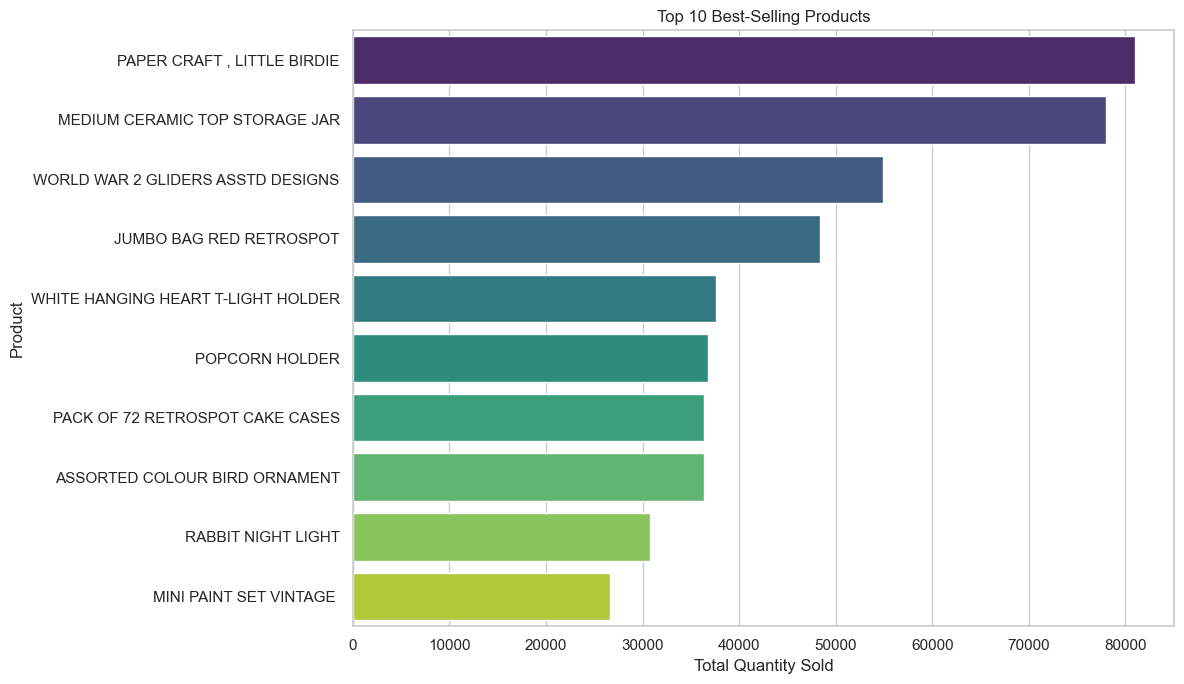

In [46]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products.reset_index(),
    x='total_quantity',
    y='description',
    hue='description',
    palette='viridis',
    legend=False
)

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [47]:
top_revenue_products = (
    sales_df.groupby(['stockcode', 'description'])['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_revenue_products)

stockcode  description                       
DOT        DOTCOM POSTAGE                        206248.77
22423      REGENCY CAKESTAND 3 TIER              174156.54
23843      PAPER CRAFT , LITTLE BIRDIE           168469.60
85123A     WHITE HANGING HEART T-LIGHT HOLDER    104284.24
47566      PARTY BUNTING                          99445.23
85099B     JUMBO BAG RED RETROSPOT                94159.81
23166      MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POST       POSTAGE                                78101.88
M          Manual                                 77750.27
23084      RABBIT NIGHT LIGHT                     66870.03
Name: revenue, dtype: float64

In [48]:
total_revenue = sales_df['revenue'].sum()

total_transactions = sales_df['invoiceno'].nunique()

average_transaction_value = (
    total_revenue / total_transactions
    if total_transactions > 0 else 0
)

print('Total Revenue:', round(total_revenue, 2))
print('Total Transactions:', total_transactions)
print('Average Transaction Value:', round(average_transaction_value, 2))

Total Revenue: 10642110.8
Total Transactions: 19960
Average Transaction Value: 533.17


In [49]:
country_revenue = (
    sales_df.groupby('country')['revenue']
    .sum()
    .sort_values(ascending=False)
)

display(country_revenue.head(10))

country
United Kingdom    9001744.094
Netherlands        285446.340
Ireland            283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: revenue, dtype: float64

In [50]:
country_revenue_pct = (
    country_revenue / country_revenue.sum() * 100
).round(2)

country_revenue_summary = pd.DataFrame({
    'Revenue': country_revenue,
    'Revenue_Percentage': country_revenue_pct
})

display(country_revenue_summary.head(10))

,Revenue,Revenue_Percentage
country,,
United Kingdom,9001744.094,84.59
Netherlands,285446.340,2.68
Ireland,283140.520,2.66
Germany,228678.400,2.15
France,209625.370,1.97
Australia,138453.810,1.30
Spain,61558.560,0.58
Switzerland,57067.600,0.54
Belgium,41196.340,0.39


In [51]:
total_customers = df['customerid'].nunique()

missing_customer_ids = df['customerid'].isna().sum()

print('Unique Customers:', total_customers)
print('Missing Customer IDs:', missing_customer_ids)

Unique Customers: 4372
Missing Customer IDs: 135037


In [52]:
customer_revenue = (
    sales_df.dropna(subset=['customerid'])
    .groupby('customerid')
    .agg(
        total_revenue=('revenue', 'sum'),
        total_quantity=('quantity', 'sum'),
        total_invoices=('invoiceno', 'nunique')
    )
    .sort_values('total_revenue', ascending=False)
)

display(customer_revenue.head(10))

,total_revenue,total_quantity,total_invoices
customerid,,,
14646.0,280206.02,196915,73
18102.0,259657.30,64124,60
17450.0,194390.79,69973,46
16446.0,168472.50,80997,2
14911.0,143711.17,80240,201
12415.0,124914.53,77374,21
14156.0,117210.08,57768,55
17511.0,91062.38,64549,31
16029.0,80850.84,40108,63


In [53]:
customer_frequency = (
    sales_df.dropna(subset=['customerid'])
    .groupby('customerid')['invoiceno']
    .nunique()
    .sort_values(ascending=False)
)

display(customer_frequency.head(10))

customerid
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: invoiceno, dtype: int64

In [54]:
cancellation_df = df[
    (df['quantity'] < 0) &
    (df['invoiceno'].astype(str).str.startswith('C'))
].copy()

display(cancellation_df.head())

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country,transaction_type,year,month,day_name,revenue
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,Cancellation,2010,December,Wednesday,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,Cancellation,2010,December,Wednesday,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,Cancellation,2010,December,Wednesday,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,Cancellation,2010,December,Wednesday,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,Cancellation,2010,December,Wednesday,-6.96


In [55]:
total_cancellations = cancellation_df['invoiceno'].nunique()

cancelled_quantity = cancellation_df['quantity'].abs().sum()

cancelled_value = (
    cancellation_df['revenue'].abs().sum()
)

print('Cancellation Invoices:', total_cancellations)
print('Cancelled Quantity:', cancelled_quantity)
print('Cancelled Value:', round(cancelled_value, 2))

Cancellation Invoices: 3836
Cancelled Quantity: 275560
Cancelled Value: 893979.73


In [56]:
top_cancelled_products = (
    cancellation_df.groupby(['stockcode', 'description'])['quantity']
    .sum()
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

display(top_cancelled_products)

stockcode  description                        
23843      PAPER CRAFT , LITTLE BIRDIE            80995
23166      MEDIUM CERAMIC TOP STORAGE JAR         74494
84347      ROTATING SILVER ANGELS T-LIGHT HLDR     9376
M          Manual                                  4066
21108      FAIRY CAKE FLANNEL ASSORTED COLOUR      3150
85123A     WHITE HANGING HEART T-LIGHT HOLDER      2578
21175      GIN + TONIC DIET METAL SIGN             2030
22920      HERB MARKER BASIL                       1527
22273      FELTCRAFT DOLL MOLLY                    1447
47566B     TEA TIME PARTY BUNTING                  1424
Name: quantity, dtype: int64

In [57]:
cancellation_country = (
    cancellation_df.groupby('country')['quantity']
    .sum()
    .abs()
    .sort_values(ascending=False)
)

display(cancellation_country.head(10))

country
United Kingdom    261044
Ireland             4786
Germany             1815
France              1623
United States       1424
Spain               1127
Netherlands          809
Japan                798
Australia            556
Sweden               446
Name: quantity, dtype: int64

In [58]:
numeric_columns = [
    'quantity',
    'unitprice',
    'revenue'
]

correlation = df[numeric_columns].corr()

display(correlation)

,quantity,unitprice,revenue
quantity,1.000000,-0.001241,0.886712
unitprice,-0.001241,1.000000,-0.162043
revenue,0.886712,-0.162043,1.000000


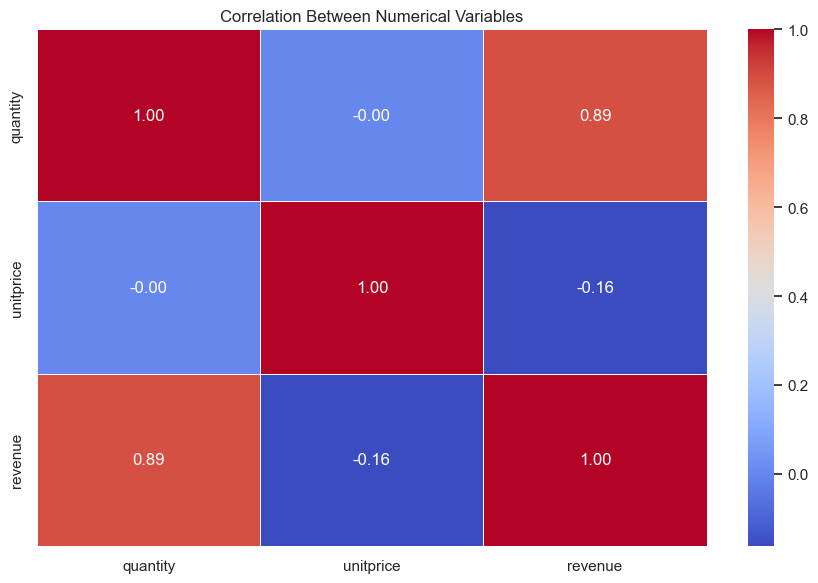

In [59]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical Variables')

plt.tight_layout()
plt.show()